# Phase 2: Exploratory Data Analysis & Data Preprocessing
**Course:** ADY201m - Applied Data Analysis  
**Objective:** Profile raw listings, quantify missing values, detect outliers via IQR fences, engineer domain features, and prepare modeling datasets.

In [3]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    display
except NameError:
    try:
        from IPython.display import display
    except ImportError:
        display = print

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    RAW_DATA_PATH,
    CLEAN_LISTINGS_PATH,
    MODEL_FEATURES_PATH,
    FIGURES_DIR,
    setup_chart_style,
    add_vnd_axis,
    to_rel_path
)
from src.features import clean_raw_dataframe, impute_cylinders, engineer_features, compute_make_tiers

setup_chart_style()
raw_df = pd.read_csv(RAW_DATA_PATH)
print(f"[*] Loaded raw listings from {to_rel_path(RAW_DATA_PATH)}: {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")
display(raw_df.head(5))


[*] Loaded raw listings from data/raw/uae_used_cars_10k.csv: 10,000 rows, 12 columns


,Make,Model,Year,Price,Mileage,Body Type,Cylinders,Transmission,Fuel Type,Color,Location,Description
0,toyota,camry,2016,47819,156500,Sedan,4,Automatic Transmission,Gasoline,Black,Dubai,"2016 toyota camry with Rear camera, Leather se..."
1,kia,sorento,2013,61250,169543,SUV,4,Automatic Transmission,Gasoline,Grey,Abu Dhabi,"2013 kia sorento with Sunroof, Adaptive cruise..."
2,mini,cooper,2023,31861,221583,Soft Top Convertible,4,Automatic Transmission,Gasoline,Grey,Dubai,"2023 mini cooper with Adaptive cruise control,..."
3,nissan,altima,2016,110322,69754,Sedan,4,Automatic Transmission,Gasoline,Red,Dubai,"2016 nissan altima with Rear camera, Adaptive ..."
4,toyota,land-cruiser-76-series,2020,139994,71399,Pick Up Truck,4,Manual Transmission,Gasoline,White,Dubai,2020 toyota land-cruiser-76-series with Adapti...


### 1. Data Type Inventory (Table 2.4)
Classify every attribute by domain data role (Numeric, Categorical, Boolean, Free Text).

In [4]:
dtypes_data = [
    {"Attribute": "Make", "Source Type": "object (string)", "Cleaned Type": "Categorical (nominal)", "Role": "Predictor"},
    {"Attribute": "Model", "Source Type": "object (string)", "Cleaned Type": "Categorical (nominal)", "Role": "Predictor"},
    {"Attribute": "Year", "Source Type": "int64", "Cleaned Type": "Discrete Numeric (car_age)", "Role": "Predictor"},
    {"Attribute": "Price", "Source Type": "int64", "Cleaned Type": "Continuous Numeric (log_price)", "Role": "Target Variable"},
    {"Attribute": "Mileage", "Source Type": "int64", "Cleaned Type": "Continuous Numeric (log_mileage)", "Role": "Predictor"},
    {"Attribute": "Body Type", "Source Type": "object (string)", "Cleaned Type": "Categorical (nominal)", "Role": "Predictor"},
    {"Attribute": "Cylinders", "Source Type": "object (mixed)", "Cleaned Type": "Discrete Numeric (imputed)", "Role": "Predictor"},
    {"Attribute": "Transmission", "Source Type": "object (string)", "Cleaned Type": "Binary Categorical", "Role": "Predictor"},
    {"Attribute": "Fuel Type", "Source Type": "object (string)", "Cleaned Type": "Categorical (nominal)", "Role": "Predictor"},
    {"Attribute": "Color", "Source Type": "object (string)", "Cleaned Type": "Categorical (nominal)", "Role": "Predictor"},
    {"Attribute": "Location", "Source Type": "object (string)", "Cleaned Type": "Categorical (region_group)", "Role": "Predictor"},
    {"Attribute": "Description", "Source Type": "object (free text)", "Cleaned Type": "Parsed Features & Condition", "Role": "Derived Indicators"}
]
df_dtypes = pd.DataFrame(dtypes_data)
display(df_dtypes)

,Attribute,Source Type,Cleaned Type,Role
0,Make,object (string),Categorical (nominal),Predictor
1,Model,object (string),Categorical (nominal),Predictor
2,Year,int64,Discrete Numeric (car_age),Predictor
3,Price,int64,Continuous Numeric (log_price),Target Variable
4,Mileage,int64,Continuous Numeric (log_mileage),Predictor
5,Body Type,object (string),Categorical (nominal),Predictor
6,Cylinders,object (mixed),Discrete Numeric (imputed),Predictor
7,Transmission,object (string),Binary Categorical,Predictor
8,Fuel Type,object (string),Categorical (nominal),Predictor
9,Color,object (string),Categorical (nominal),Predictor


### 2. Descriptive Statistics (Tables 2.5 and 2.6)
Statistical profiling for both numeric and categorical variables before transformations.

In [6]:
# Table 2.5: Numeric Columns
num_cols = ["Year", "Price", "Mileage"]
tbl_2_5 = raw_df[num_cols].describe(percentiles=[0.5]).T[["count", "mean", "50%", "std", "min", "max"]]
tbl_2_5.rename(columns={"50%": "median"}, inplace=True)
tbl_2_5["skewness"] = raw_df[num_cols].skew()
display(tbl_2_5.round(2))

,count,mean,median,std,min,max,skewness
Year,10000.0,2014.47,2014.0,5.79,2005.0,2024.0,0.00
Price,10000.0,245234.51,102766.0,470977.35,7183.0,14686975.0,9.28
Mileage,10000.0,155161.87,154370.5,83681.86,10006.0,299996.0,0.00


In [7]:
# Table 2.6: Categorical Columns
cat_cols = ["Make", "Model", "Body Type", "Cylinders", "Transmission", "Fuel Type", "Color", "Location"]
cat_rows = []
for col in cat_cols:
    s = raw_df[col].astype(str).str.strip()
    m = s.mode()[0]
    f = (s == m).sum()
    cat_rows.append({
        "Attribute": col,
        "Distinct Values": raw_df[col].nunique(),
        "Modal Class": m,
        "Modal Frequency": f,
        "Modal Share (%)": round(100.0 * f / len(raw_df), 2)
    })
tbl_2_6 = pd.DataFrame(cat_rows)
display(tbl_2_6)

,Attribute,Distinct Values,Modal Class,Modal Frequency,Modal Share (%)
0,Make,65,mercedes-benz,1486,14.86
1,Model,488,patrol,386,3.86
2,Body Type,13,SUV,4607,46.07
3,Cylinders,8,6,3420,34.20
4,Transmission,2,Automatic Transmission,9626,96.26
5,Fuel Type,4,Gasoline,9714,97.14
6,Color,17,White,3355,33.55
7,Location,16,Dubai,8011,80.11


### 3. Exploratory Visualizations (Figures 2.2 and 2.3)
Examine raw vs. log-transformed price distribution and listing count breakdown by body style.

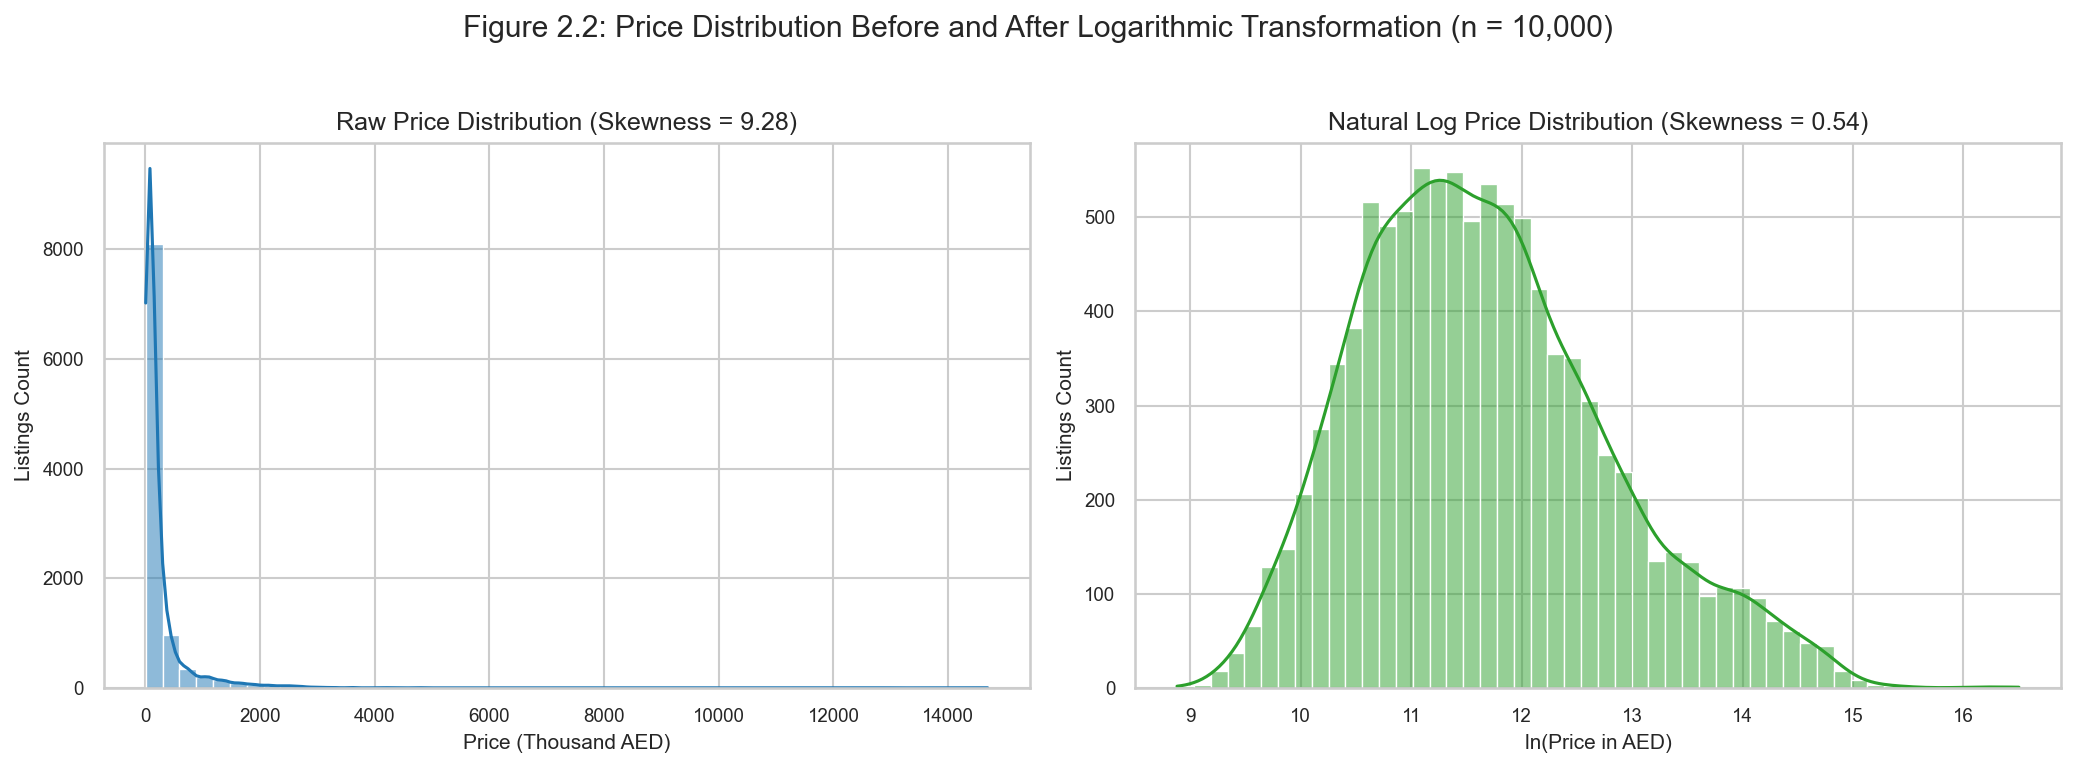

In [9]:
# Figure 2.2: Price distribution raw vs log
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(raw_df["Price"] / 1e3, bins=50, kde=True, ax=ax1, color="#1f77b4")
ax1.set_title("Raw Price Distribution (Skewness = 9.28)")
ax1.set_xlabel("Price (Thousand AED)")
ax1.set_ylabel("Listings Count")

sns.histplot(np.log(raw_df["Price"]), bins=50, kde=True, ax=ax2, color="#2ca02c")
ax2.set_title("Natural Log Price Distribution (Skewness = 0.54)")
ax2.set_xlabel("ln(Price in AED)")
ax2.set_ylabel("Listings Count")
fig.suptitle("Figure 2.2: Price Distribution Before and After Logarithmic Transformation (n = 10,000)", y=1.02)
fig.savefig(FIGURES_DIR / "fig_2_2_price_distribution_raw_vs_log.png", dpi=150, bbox_inches="tight")
plt.show()

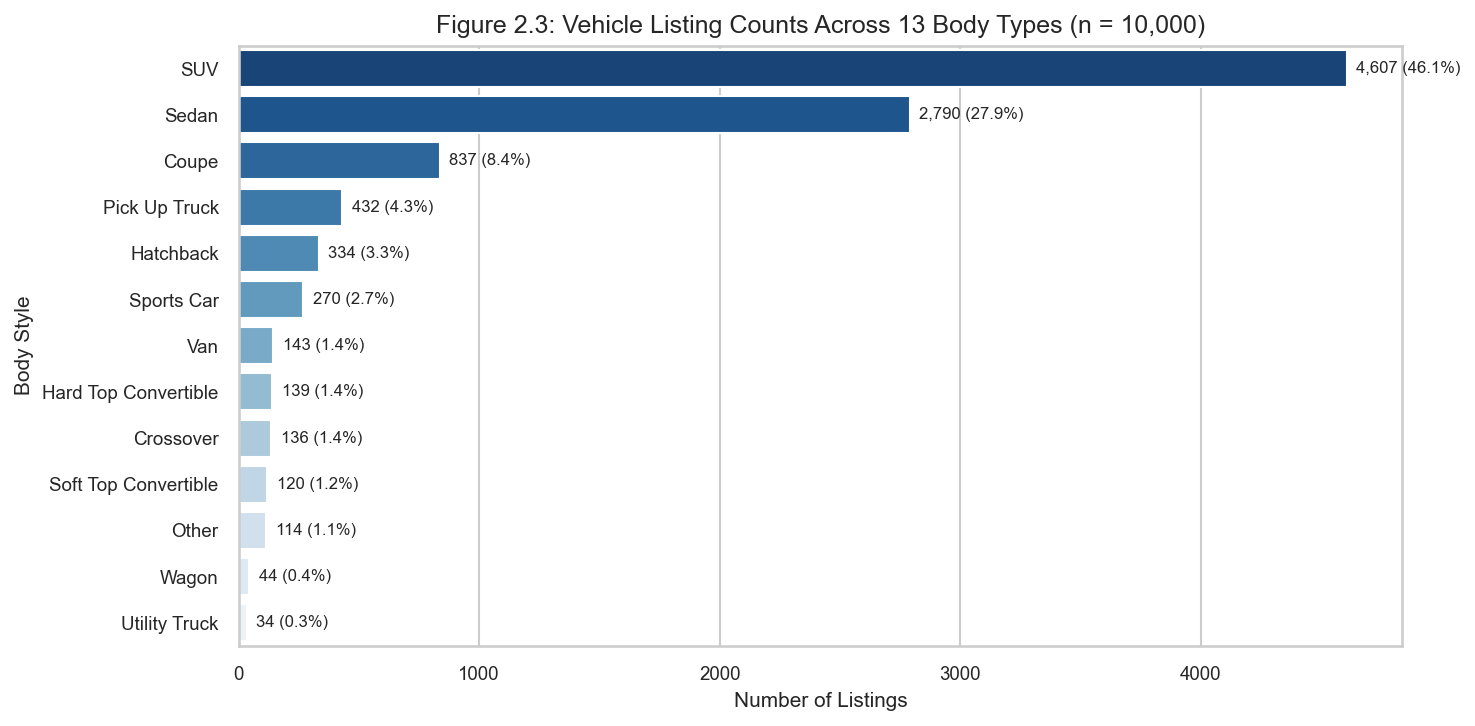

In [10]:
# Figure 2.3: Listings by Body Style
plt.figure(figsize=(10, 5))
bt_counts = raw_df["Body Type"].str.strip().value_counts()
ax = sns.barplot(x=bt_counts.values, y=bt_counts.index, hue=bt_counts.index, palette="Blues_r", legend=False)
plt.title("Figure 2.3: Vehicle Listing Counts Across 13 Body Types (n = 10,000)")
plt.xlabel("Number of Listings")
plt.ylabel("Body Style")
for i, v in enumerate(bt_counts.values):
    ax.text(v + 40, i, f"{v:,} ({v/100:.1f}%)", va="center", fontsize=8)
plt.savefig(FIGURES_DIR / "fig_2_3_listings_per_body_type.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Missing Value Treatment (Table 2.7)
Quantify missing values before and after group-mode hierarchical imputation on .

In [11]:
cleaned_df = clean_raw_dataframe(raw_df)
before_na = cleaned_df[["price_aed", "model_year", "mileage_km", "cylinders", "body_type", "transmission", "fuel_type", "location", "condition"]].isna().sum()

imputed_df = impute_cylinders(cleaned_df)
after_na = imputed_df[["price_aed", "model_year", "mileage_km", "cylinders", "body_type", "transmission", "fuel_type", "location", "condition"]].isna().sum()

tbl_2_7 = pd.DataFrame({
    "Missing Before (Count)": before_na,
    "Missing Before (%)": (before_na / 100).round(2),
    "Missing After (Count)": after_na,
    "Missing After (%)": (after_na / 100).round(2)
})
display(tbl_2_7)

,Missing Before (Count),Missing Before (%),Missing After (Count),Missing After (%)
price_aed,0,0.00,0,0.0
model_year,0,0.00,0,0.0
mileage_km,0,0.00,0,0.0
cylinders,155,1.55,0,0.0
body_type,0,0.00,0,0.0
transmission,0,0.00,0,0.0
fuel_type,0,0.00,0,0.0
location,0,0.00,0,0.0
condition,0,0.00,0,0.0


### 5. Outlier Detection with 1.5× IQR Fences (Figure 2.4)
Evaluate distribution extremes on both raw and logarithmic scales.

Raw Price Fence: Upper = 502,591.2 AED | Outliers = 1100 (11.0%)
Log Price Fences: [8.540, 14.638] (AED: [5,116, 2,275,954]) | Outliers = 91 (0.9%)


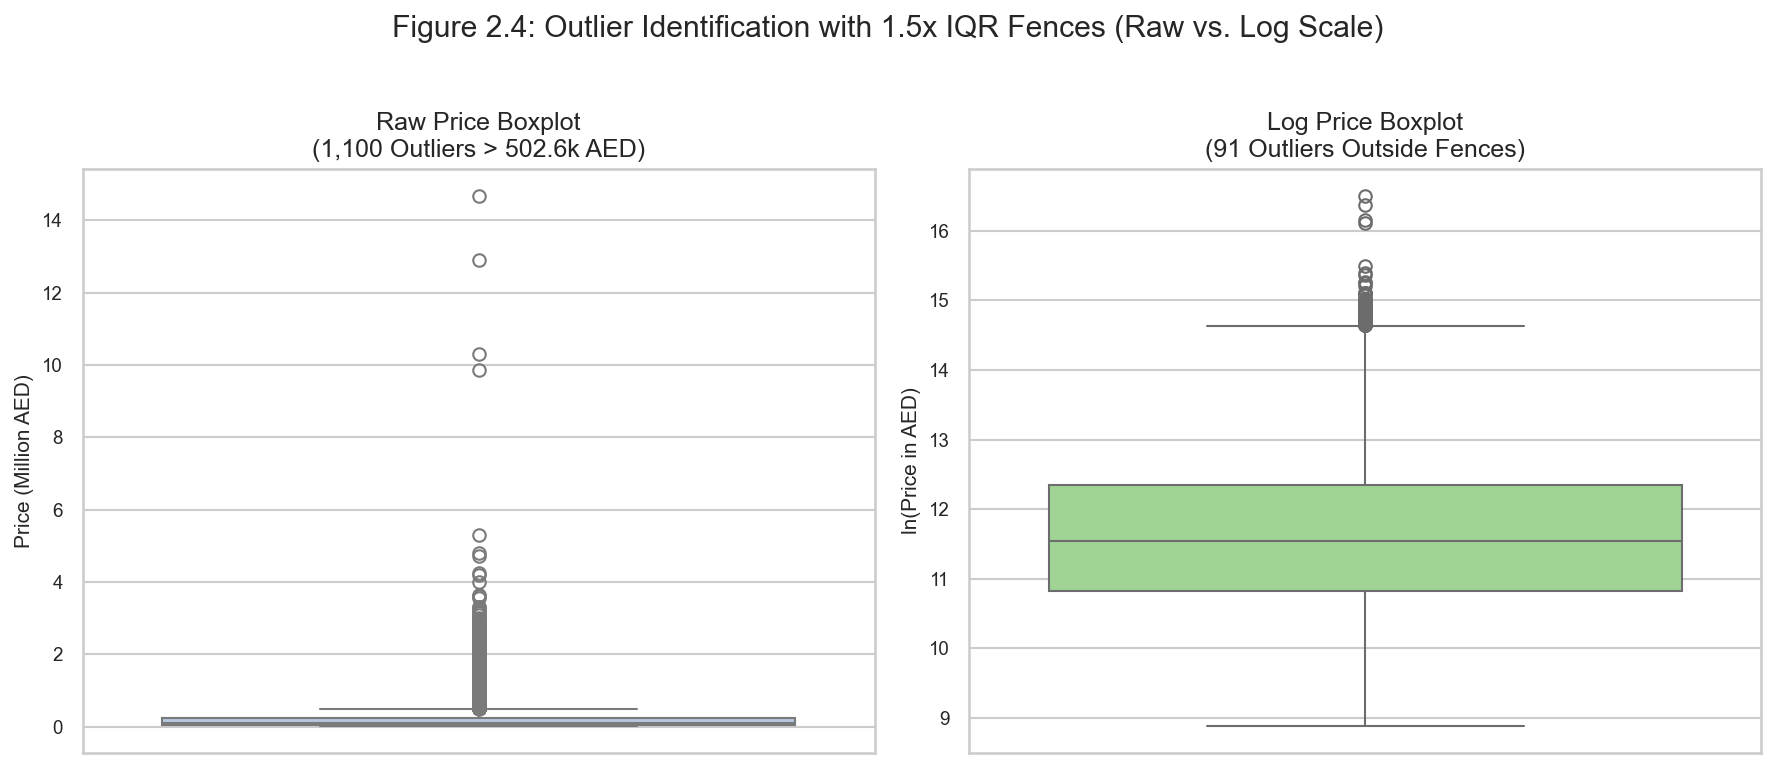

In [13]:

# Raw IQR Fences
q1_p, q3_p = raw_df["Price"].quantile([0.25, 0.75])
iqr_p = q3_p - q1_p
upper_raw = q3_p + 1.5 * iqr_p
n_raw_outliers = (raw_df["Price"] > upper_raw).sum()

# Log IQR Fences
log_p = np.log(raw_df["Price"])
q1_lp, q3_lp = log_p.quantile([0.25, 0.75])
iqr_lp = q3_lp - q1_lp
lower_log = q1_lp - 1.5 * iqr_lp
upper_log = q3_lp + 1.5 * iqr_lp

n_log_outliers = (
    (log_p < lower_log) | (log_p > upper_log)
).sum()

# Print Outlier Statistics
print(
    f"Raw Price Fence: Upper = {upper_raw:,.1f} AED | "
    f"Outliers = {n_raw_outliers} ({n_raw_outliers/len(raw_df)*100:.1f}%)"
)

print(
    f"Log Price Fences: [{lower_log:.3f}, {upper_log:.3f}] "
    f"(AED: [{np.exp(lower_log):,.0f}, {np.exp(upper_log):,.0f}]) | "
    f"Outliers = {n_log_outliers} "
    f"({n_log_outliers/len(raw_df)*100:.1f}%)"
)

# Create Boxplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Raw Price Boxplot
sns.boxplot(
    y=raw_df["Price"] / 1e6,
    ax=ax1,
    color="#aec7e8"
)

ax1.set_title(
    f"Raw Price Boxplot\n"
    f"({n_raw_outliers:,} Outliers > {upper_raw/1e3:,.1f}k AED)"
)
ax1.set_ylabel("Price (Million AED)")

# Log Price Boxplot
sns.boxplot(
    y=log_p,
    ax=ax2,
    color="#98df8a"
)

ax2.set_title(
    f"Log Price Boxplot\n"
    f"({n_log_outliers:,} Outliers Outside Fences)"
)
ax2.set_ylabel("ln(Price in AED)")

# Figure Title and Save
fig.suptitle(
    "Figure 2.4: Outlier Identification with 1.5x IQR Fences (Raw vs. Log Scale)",
    y=1.02
)

fig.savefig(
    FIGURES_DIR / "fig_2_4_outlier_boxplots.png",
    dpi=150,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()


### 6. Feature Engineering & Dataset Export (Gate G1)
Generate all engineered variables, map make price tiers, and export  and .

In [14]:
features_df = engineer_features(imputed_df)
features_df, tier_map = compute_make_tiers(features_df)

print("[*] Final Engineered Features:", [c for c in features_df.columns if c not in raw_df.columns])
print(f"[*] Total rows: {len(features_df):,} | Implausible usage rows (>50k km/yr): {features_df['implausible_usage'].sum():,}")

features_df.to_csv(CLEAN_LISTINGS_PATH, index=False)
features_df.to_csv(MODEL_FEATURES_PATH, index=False)
print(f"[+] Exported clean listings: {to_rel_path(CLEAN_LISTINGS_PATH)}")
print(f"[+] Exported modeling features: {to_rel_path(MODEL_FEATURES_PATH)}")

[*] Final Engineered Features: ['make', 'model', 'model_year', 'price_aed', 'mileage_km', 'body_type', 'cylinders', 'transmission', 'fuel_type', 'color', 'location', 'description', 'cylinders_raw', 'features_list', 'condition', 'cylinders_imputed', 'car_age', 'mileage_per_year', 'log_mileage', 'log_price', 'price_vnd', 'n_features', 'has_sunroof', 'has_leather_seats', 'has_navigation', 'has_bluetooth', 'has_rear_camera', 'has_adaptive_cruise', 'is_accident_history', 'region_group', 'implausible_usage', 'make_tier']
[*] Total rows: 10,000 | Implausible usage rows (>50k km/yr): 1,268
[+] Exported clean listings: data/interim/clean_listings.csv
[+] Exported modeling features: data/processed/model_features.csv
